In [3]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:


df = sns.load_dataset('titanic')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [5]:
df.shape

(891, 15)

In [6]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [ ]:
df['age']=df['age'].fillna(df['age'].median())
# filling age with mean because there are outlier present in the age column

In [ ]:
#droping deck because more than 50% rows are empty filling this columns with mode is not good for our analysis
df=df.drop('deck', axis=1)

In [9]:
df.duplicated().sum()

np.int64(111)

In [10]:
df=df.drop_duplicates()

In [11]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,780.000000,780.000000,780.000000,780.000000,780.000000,780.000000
mean,0.412821,2.246154,29.797600,0.525641,0.417949,34.829108
std,0.492657,0.854452,13.708883,0.988046,0.838536,52.263440
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,21.750000,0.000000,0.000000,8.050000
50%,0.000000,3.000000,29.699118,0.000000,0.000000,15.950000
75%,1.000000,3.000000,36.000000,1.000000,1.000000,34.375000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


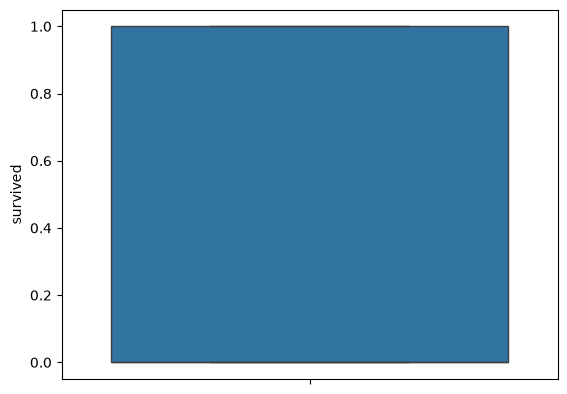

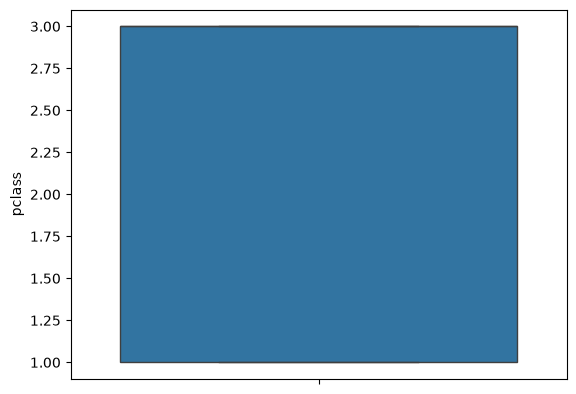

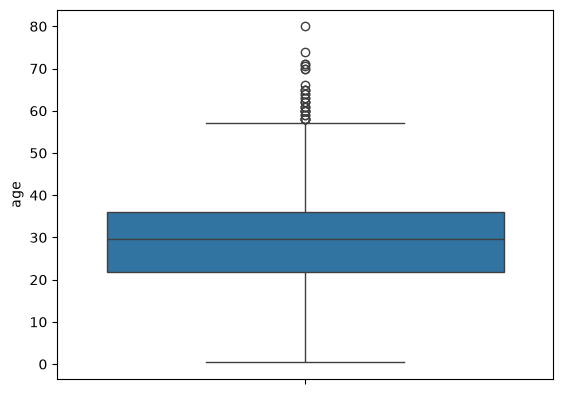

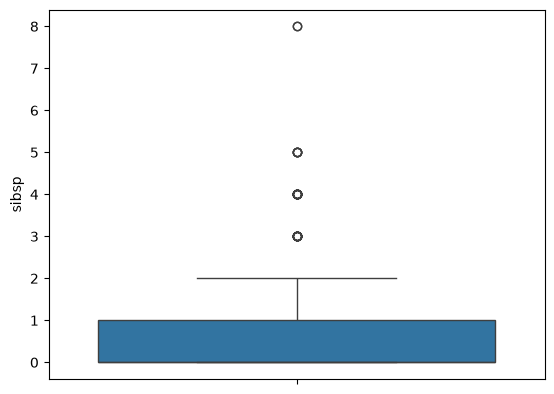

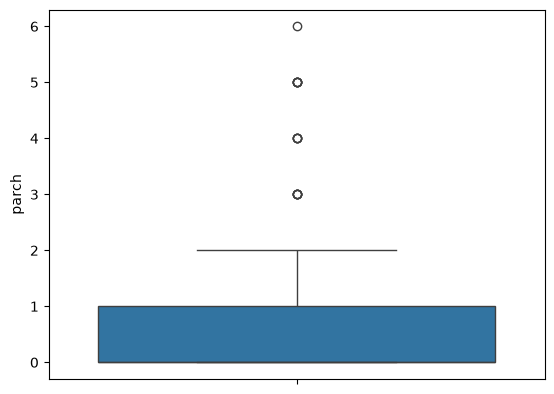

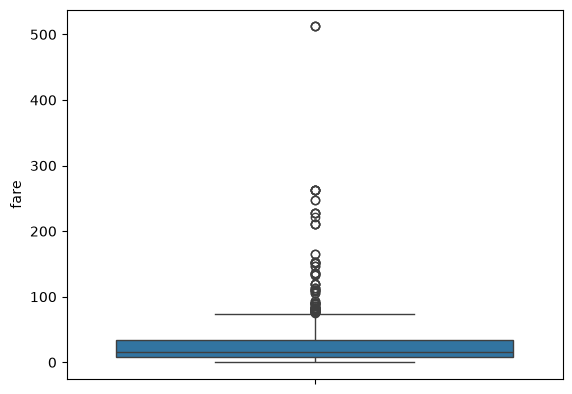

In [ ]:
for i in df.select_dtypes(include= 'number').columns:
    
    sns.boxplot(df[i])
    plt.show()
#checking outliers 

In [ ]:
# above chart proves that there are lots of outliers present in the data

In [13]:

q1= df['fare'].quantile(0.25)
q3= df['fare'].quantile(0.75)

iqr= q3-q1
upper_whisker= q3 + 1.5*iqr
lower_whisker= q1 - 1.5*iqr


df['outliers_in_orc'] = np.where((df['fare']> upper_whisker) | (df['fare']<lower_whisker), 'outlier','notoutlier')

In [15]:
df.shape

(780, 15)

<Axes: xlabel='class'>

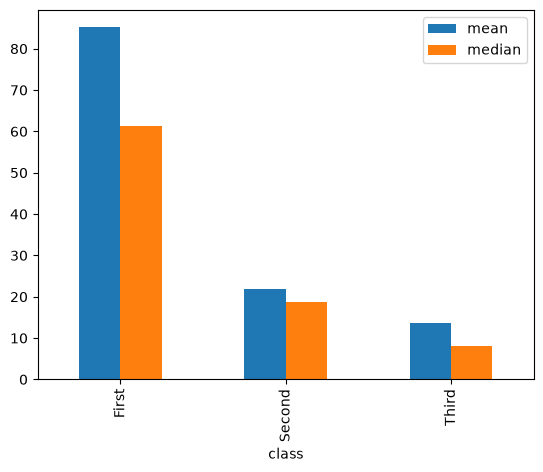

In [ ]:
df.groupby(['class'])['fare'].agg(['mean','median']).plot(kind='bar')
#checking class wise fare if different class cost more 
# chart proves that first class cost way more

<Axes: xlabel='embark_town'>

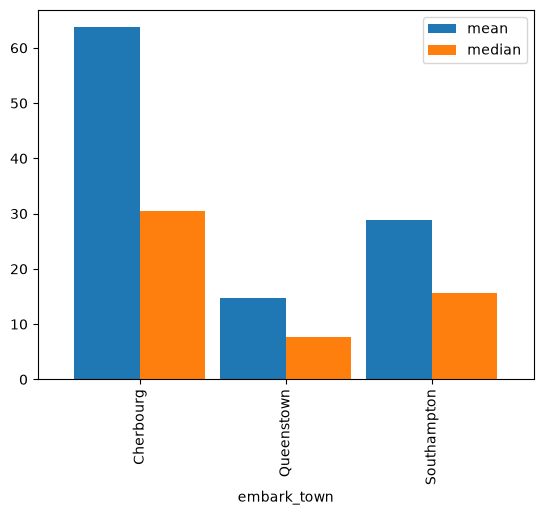

In [ ]:
df.groupby(['embark_town'])['fare'].agg(['mean','median']).plot(kind='bar', width=0.9)


In [18]:
def age_category(age):
    if pd.isna(age):
        return 'Unknown'
    elif age < 5:
        return '0-5'
    elif age < 10:
        return '5-10'
    elif age < 15:
        return '10-15'
    elif age < 20:
        return '15-20'
    elif age < 25:
        return '20-25'
    elif age < 30:
        return '25-30'
    elif age < 35:
        return '30-35'
    elif age < 40:
        return '35-40'
    elif age < 45:
        return '40-45'
    elif age < 50:
        return '45-50'
    elif age < 55:
        return '50-55'
    elif age < 60:
        return '55-60'
    elif age < 65:
        return '60-65'
    elif age < 70:
        return '65-70'
    elif age < 75:
        return '70-75'
    elif age < 90:
        return '75-90'
    else:
        return '90+'

df['Age_Category'] = df['age'].apply(age_category)

In [19]:

dataset=df.groupby(['Age_Category'])['fare'].agg(['mean','median','count']).reset_index()

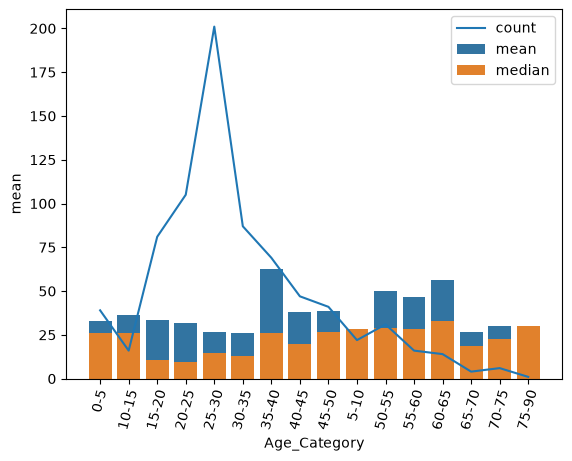

In [ ]:
sns.barplot(x='Age_Category',y='mean',data=dataset,label= 'mean')
sns.barplot(x='Age_Category',y='median',data=dataset, label= 'median')
sns.lineplot(x='Age_Category',y='count',data= dataset, label= 'count')
plt.xticks(rotation= 75)
plt.legend()
# checking age category wise fare distribution , below figure tells us that from 20 to 30 most of our data
# is present  which means most of the passenger are from this age group and also another thing this chart shows us, is that till 35 
# people after the age of 35 paid more. 

In [21]:
sns.set_theme(style='whitegrid', palette='viridis', font_scale=1.2)

In [22]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,outliers_in_orc,Age_Category
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False,notoutlier,20-25
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False,notoutlier,35-40
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True,notoutlier,25-30
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False,notoutlier,35-40
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True,notoutlier,35-40


sns.histplot(df['fare])

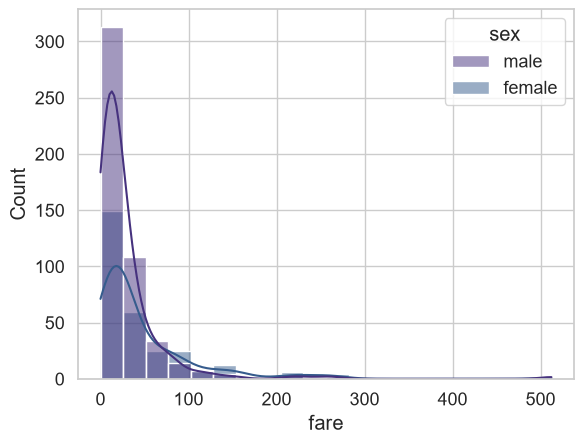

In [ ]:
sns.histplot(data=df, x='fare', hue='sex',kde = True, bins=20)
plt.show()

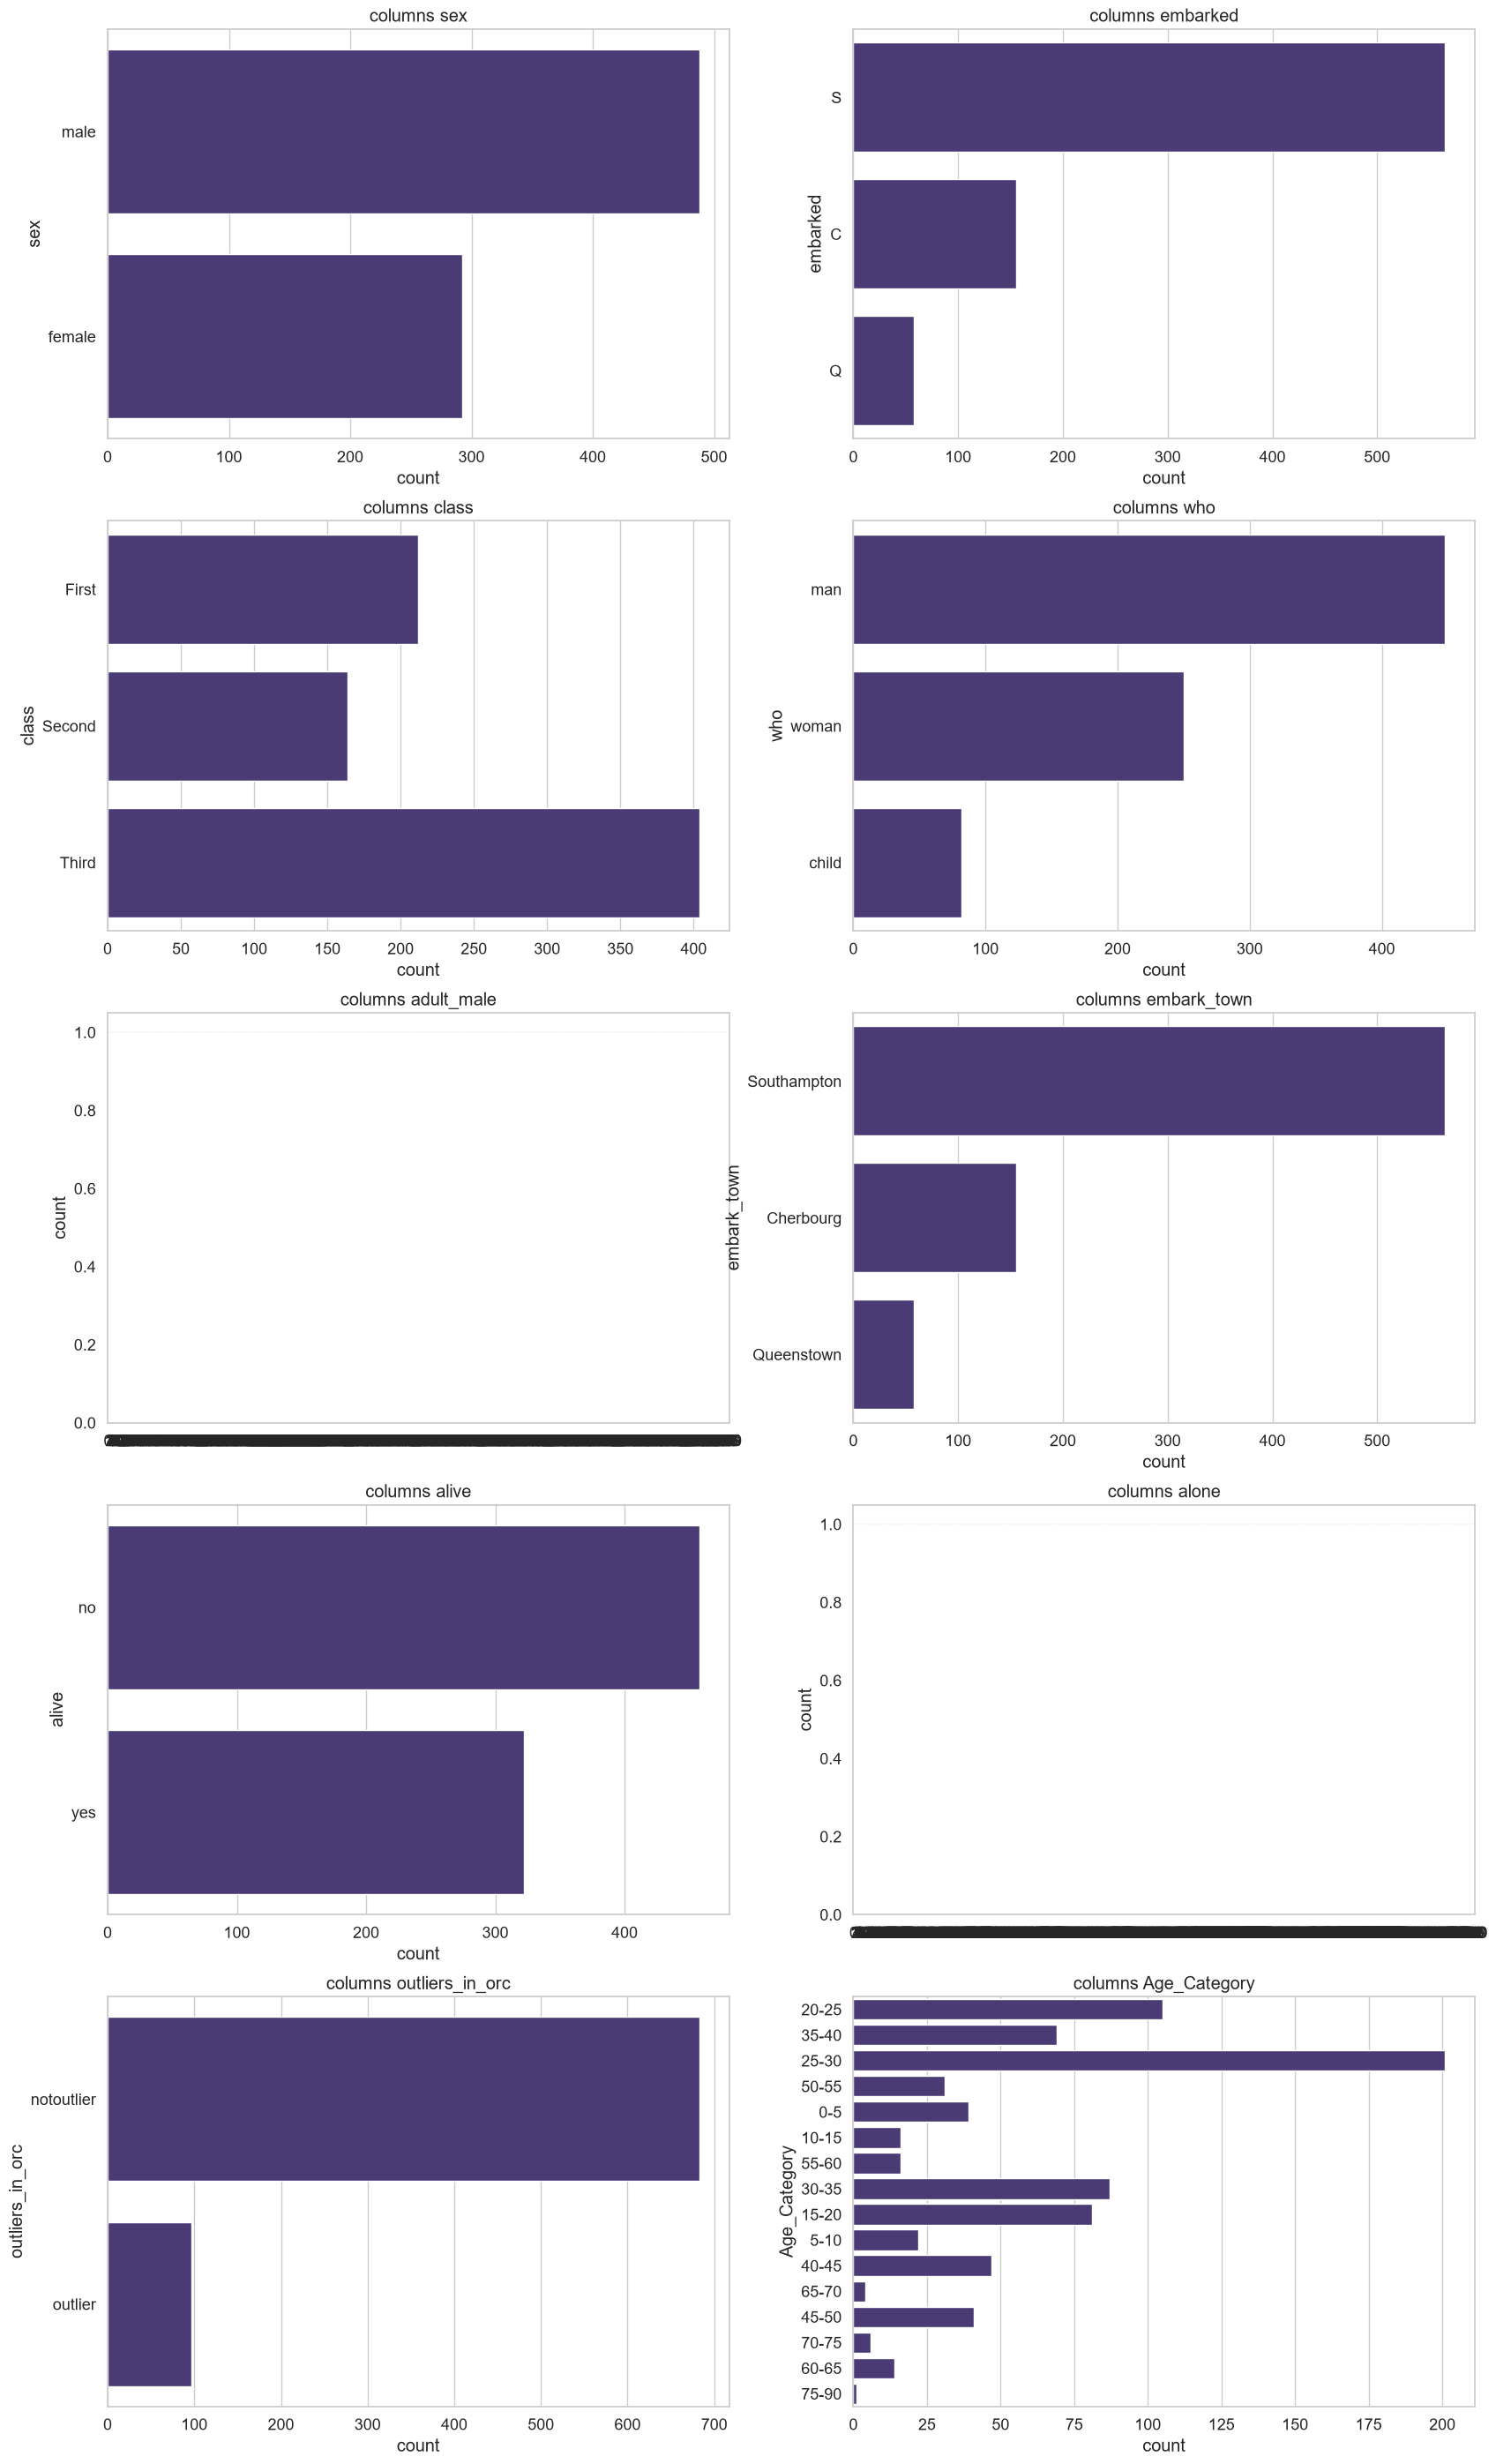

In [45]:

col= df.select_dtypes(exclude='number').columns
plt.figure(figsize=(20,35))
for i ,j in enumerate(col):
    plt.subplot(5,2,i+1)
    sns.countplot(df[j])
    plt.title(f"columns {j}")
plt.show()


In [46]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,outliers_in_orc,Age_Category
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False,notoutlier,20-25
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False,notoutlier,35-40
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True,notoutlier,25-30
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False,notoutlier,35-40
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True,notoutlier,35-40


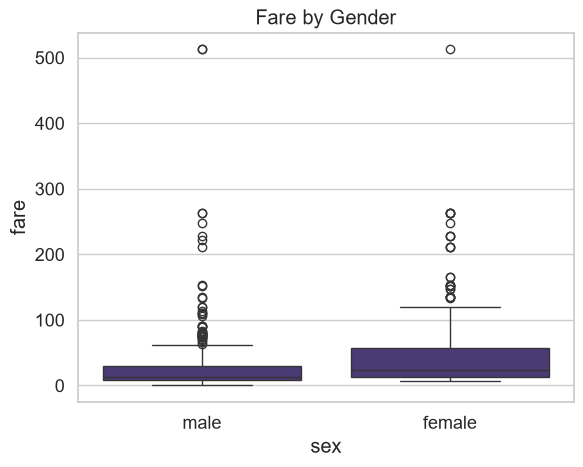

In [47]:
sns.boxplot(data=df, x='sex', y='fare')
plt.title('Fare by Gender')
plt.show()

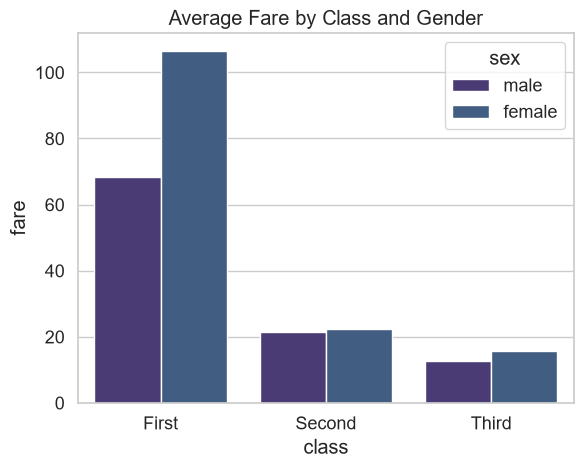

In [ ]:
sns.barplot(
    data=df,
    x='class',
    y='fare',
    hue='sex',
    errorbar=None
)
plt.title('Average Fare by Class and Gender')
plt.show()
# this shows women paid more than men most of the times

In [51]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,outliers_in_orc,Age_Category
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False,notoutlier,20-25
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False,notoutlier,35-40
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True,notoutlier,25-30
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False,notoutlier,35-40
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True,notoutlier,35-40


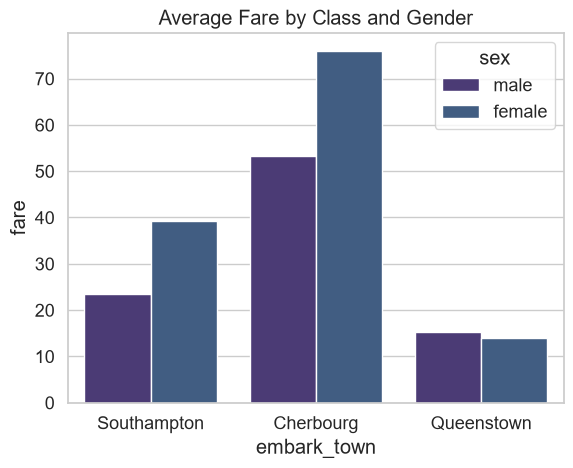

In [52]:
sns.barplot(
    data=df,
    x='embark_town',
    y='fare',
    hue='sex',
    errorbar=None
)
plt.title('Average Fare by Class and Gender')
plt.show()
# this shows women paid more than men most of the times

In [53]:
df['sex'].value_counts()

sex
male      488
female    292
Name: count, dtype: int64